# Homework 4: Evaluation Metrics for Classification

* Dataset: https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [20]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [21]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [22]:
!wget $data -O data-week-4.csv 

--2026-10-26 12:45:06--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘data-week-4.csv’

data-week-4.csv     100%[===================>] 272.21K  --.-KB/s    in 0.07s   

2026-10-26 12:45:07 (3.77 MB/s) - ‘data-week-4.csv’ saved [278746/278746]



In [23]:
df = pd.read_csv('data-week-4.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [25]:
# Check missing values.
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [26]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [27]:
# Replace missing values from categorical features with 'NA'
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']
df[categorical_cols] = df[categorical_cols].fillna('NA')
df.isnull().sum()

lead_source                   0
industry                      0
employment_status             0
location                      0
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [28]:
# Replace missing values from numerical features with 0.0
numerical_cols = ['annual_income', 'lead_score']
df[numerical_cols] = df[numerical_cols].fillna(0.0)
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [29]:
# This safely targets both older 'object' text and newer 'string' text
categorical_columns = list(df.select_dtypes(include=['object', 'string']).columns)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_') # Standardizes object column data.

In [30]:
df.head().T  # Transposes the first 5 rows of the DataFrame for easier vertical reading

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,na,north_america
annual_income,88160.0,72688.0,44697.0,0.0,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [31]:
# Check unique values
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

lead_source
<StringArray>
['organic_search', 'social_media', 'referral', 'paid_ads', 'na']
Length: 5, dtype: str
6

industry
<StringArray>
['technology', 'retail', 'manufacturing', 'education', 'healthcare']
Length: 5, dtype: str
7

employment_status
<StringArray>
['employed', 'student', 'na', 'unemployed', 'self_employed']
Length: 5, dtype: str
5

location
<StringArray>
['europe', 'south_america', 'na', 'north_america', 'africa']
Length: 5, dtype: str
6

annual_income
[88160. 72688. 44697.     0. 24062.]
4314

number_of_courses_viewed
[3 4 2 1 0]
7

interaction_count
[4 7 6 5 9]
14

lead_score
[0.64 0.72 0.58 0.57 0.62]
100

converted
[1 0]
2



In [32]:
numerical_columns = ['annual_income', 'interaction_count', 'number_of_courses_viewed', 'lead_score']

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [34]:
# Splits the original dataset, setting aside 20% for testing and keeping the remaining 80% as the full training set.
# Setting random_state=1 ensures the random shuffle is reproducible if the notebook is run again (i.e. seeding).
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# Splits the 80% full training set into the final training set and a validation set. 
# The test_size=0.25 parameter is used because 25% of the 80% full training data equals exactly 20% of the original dataset.
# This two-step process results in the desired 60/20/20 split: 60% for training, 20% for validation, and 20% for testing.
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [35]:
len(df_train), len(df_val), len(df_test) # Confirming dataset sizes

(3000, 1000, 1000)

In [36]:
df_train = df_train.reset_index(drop=True) # Gives a new index and drop true avoids the old index being added as a new column.
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2,na,finance,employed,na,76300.0,0,3,0.42,0
3,paid_ads,finance,employed,na,80371.0,2,6,0.49,0
4,organic_search,finance,employed,asia,73567.0,2,4,0.48,1


In [37]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']
y_train

array([1, 0, 0, ..., 0, 1, 1], shape=(3000,))

In [38]:
# One-hot encoding creates mostly 0s, so it defaults to a memory-efficient sparse matrix that only stores 1s.
# Setting sparse=False forces a dense NumPy array instead, which is easier to work with for this dataset.
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_cols + numerical_columns].to_dict(orient='records')
X_train = dv.fit_transform(train_dict) # fit learns the list of categories for each column, fit_transform does both in one call

val_dict = df_val[categorical_cols + numerical_columns].to_dict(orient='records')
X_val = dv.transform(val_dict) # transform reuses the previous fit and turns dictionaries into a matrix

In [39]:
X_train.shape

(3000, 28)

In [40]:
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000,
    random_state=1
)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1

In [41]:
y_pred = model.predict_proba(X_val)[:, 1]
conversion = (y_pred >= 0.5)
(y_val == conversion).mean()

np.float64(0.651)

In [42]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

In [43]:
auc_scores = {}

for feature in numerical_columns:
    # Calculate initial ROC AUC using the raw feature values
    auc = roc_auc_score(y_train, df_train[feature])

    # If AUC < 0.5, the feature is negatively correlated with the target.
    # Invert it (-) to flip the direction, making the score meaningful for ranking.
    # Negative correlation still has predictive power
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    auc_scores[feature] = auc

auc_scores

{'annual_income': 0.6081977776250831,
 'interaction_count': 0.7649203047563227,
 'number_of_courses_viewed': 0.7229894623989618,
 'lead_score': 0.7882254810906102}

In [44]:
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

round(auc, 3)

0.732

## Question 3: Precision and Recall



In [45]:
thresholds = np.linspace(0, 1, 101)

scores = []

for threshold in thresholds:
    actual_positive = y_val == 1
    actual_negative = y_val == 0

    predict_positive = y_pred >= threshold
    predict_negative = y_pred < threshold

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0 # Precision : From the `pre`dicted positives, how many we predicted right out of our positive predictions
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0 # Recall : From the `re` `al` positives, how many we predicted right out of the actual true occurences 

    scores.append((threshold, precision, recall))

columns = ["threshold", "precision", "recall"]

df_scores = pd.DataFrame(scores, columns=columns)

df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


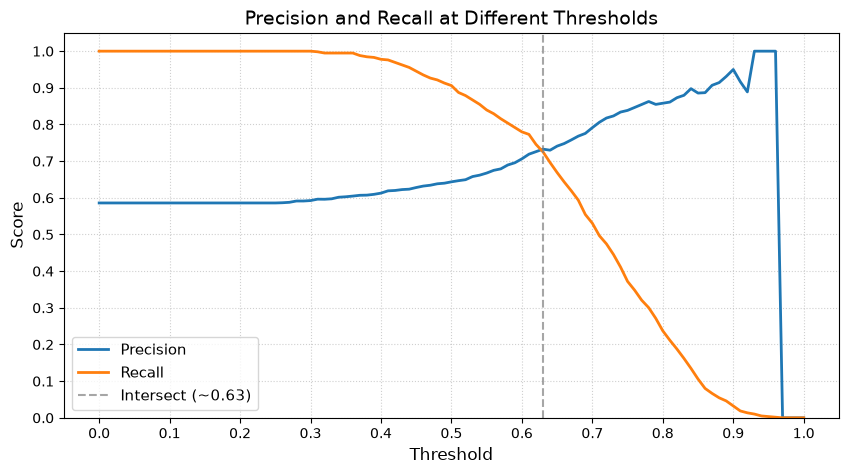

In [46]:
plt.figure(figsize=(10, 5))

# Plot precision and recall
plt.plot(
    df_scores["threshold"],
    df_scores["precision"],
    label="Precision",
    linewidth=2
)
plt.plot(
    df_scores["threshold"],
    df_scores["recall"],
    label="Recall",
    linewidth=2
)

intersect_threshold = 0.63

plt.axvline(
    x=intersect_threshold, 
    color='gray', 
    linestyle='--', 
    alpha=0.7, 
    label=f'Intersect (~{intersect_threshold})'
)

# Add more granular markings/ticks on the axes
plt.xticks(np.arange(0, 1.1, 0.1))  # Marks every 0.1 from 0 to 1 on the X-axis
plt.yticks(np.arange(0, 1.1, 0.1))  # Marks every 0.1 from 0 to 1 on the Y-axis

# Labels, title, grid, and legend
plt.xlabel("Threshold", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.title("Precision and Recall at Different Thresholds", fontsize=14)

plt.grid(True, linestyle=":", alpha=0.6)
plt.ylim(0, 1.05)
plt.legend(fontsize=11)

plt.show()

In [47]:
# 1. Filter out dead zones: remove rows where BOTH precision and recall are 0.
# The tilde (~) means "NOT", so we keep all other valid thresholds.
df_nonzero = df_scores[
    ~((df_scores["precision"] == 0) & (df_scores["recall"] == 0))
].copy()

# 2. Calculate the absolute gap between precision and recall for each threshold.
df_nonzero["difference"] = (
    df_nonzero["precision"] - df_nonzero["recall"]
).abs()

# 3. Find the threshold where precision and recall are closest (smallest difference).
# .idxmin() gets the index of the minimum difference, and .loc retrieves that row.
df_nonzero.loc[
    df_nonzero["difference"].idxmin()
]

threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64

## Question 4: F1 score


In [48]:
df_scores["f1"] = (
    2
    * df_scores["precision"]
    * df_scores["recall"]
    / (df_scores["precision"] + df_scores["recall"])
).fillna(0)

df_scores.head()

,threshold,precision,recall,f1
0,0.00,0.586,1.0,0.738966
1,0.01,0.586,1.0,0.738966
2,0.02,0.586,1.0,0.738966
3,0.03,0.586,1.0,0.738966
4,0.04,0.586,1.0,0.738966


In [49]:
df_scores.loc[df_scores["f1"].idxmax()]

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

## Question 5: 5-Fold CV



In [50]:
y_full_train = df_full_train['converted'].values
df_full_train_X = df_full_train.drop(columns=['converted'])

In [51]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

auc_scores_cv = []

for train_idx, val_idx in kfold.split(df_full_train_X):
    df_train_fold = df_full_train_X.iloc[train_idx]
    df_val_fold = df_full_train_X.iloc[val_idx]

    y_train_fold = y_full_train[train_idx]
    y_val_fold = y_full_train[val_idx]

    dv_fold = DictVectorizer(sparse=False)
    X_train_fold = dv_fold.fit_transform(df_train_fold.to_dict(orient="records"))
    X_val_fold = dv_fold.transform(df_val_fold.to_dict(orient="records"))

    model_fold = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=1)
    model_fold.fit(X_train_fold, y_train_fold)

    y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]
    auc_scores_cv.append(roc_auc_score(y_val_fold, y_pred_fold))

auc_scores_cv

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [52]:
round(np.std(auc_scores_cv), 3)

np.float64(0.007)

## Question 6: Hyperparameter Tuning



In [53]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    auc_scores_c = []

    for train_idx, val_idx in kfold.split(df_full_train_X):
        df_train_fold = df_full_train_X.iloc[train_idx]
        df_val_fold = df_full_train_X.iloc[val_idx]

        y_train_fold = y_full_train[train_idx]
        y_val_fold = y_full_train[val_idx]

        dv_fold = DictVectorizer(sparse=False)
        X_train_fold = dv_fold.fit_transform(df_train_fold.to_dict(orient="records"))
        X_val_fold = dv_fold.transform(df_val_fold.to_dict(orient="records"))

        model_fold = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=1)
        model_fold.fit(X_train_fold, y_train_fold)

        y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]
        auc_scores_c.append(roc_auc_score(y_val_fold, y_pred_fold))

    print(f"C={C:<8} Mean AUC: {np.mean(auc_scores_c):.3f} ± {np.std(auc_scores_c):.3f}")

C=1e-06    Mean AUC: 0.617 ± 0.019
C=0.001    Mean AUC: 0.749 ± 0.010
C=1        Mean AUC: 0.732 ± 0.007
